<a href="https://colab.research.google.com/github/alwahabatheer-wq/SpeechProcessingCourse/blob/main/task1_yes_no_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Yes/No Audio Classification
**Digital Speech Processing** | Classical classifiers on MFCC-based features

Pipeline: dataset discovery → speaker-disjoint split → feature extraction → hyperparameter tuning on the validation set → single test evaluation → cross-validation → error analysis.

In [1]:
%pip install -q librosa soundfile

In [2]:
import os, random, warnings, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, librosa.display
import soundfile as sf
from joblib import Parallel, delayed

from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import ParameterGrid, GroupShuffleSplit, GroupKFold, train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

warnings.filterwarnings("ignore")
SEED, SR = 42, 16000
N = SR                              # fixed length: 1 s at 16 kHz
CLASSES = ["no", "yes"]             # label 0 = no, label 1 = yes
np.random.seed(SEED); random.seed(SEED)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

## 1. Dataset
Set `ROOT` to the folder where the Yes/No data lives (searched recursively; class = name of the parent folder). If nothing is found there, Google Speech Commands v0.02 is downloaded via torchaudio.

In [3]:
ROOT = "/content/data"              # <-- change to your dataset folder
DOWNLOAD_IF_MISSING = True

def has_audio(root):
    return Path(root).exists() and any(Path(root).rglob("*.wav"))

if not has_audio(ROOT) and DOWNLOAD_IF_MISSING:
    import torchaudio
    os.makedirs(ROOT, exist_ok=True)
    torchaudio.datasets.SPEECHCOMMANDS(ROOT, download=True)

rows = [(str(p), p.parent.name.lower()) for p in Path(ROOT).rglob("*")
        if p.suffix.lower() in {".wav", ".flac"} and p.parent.name.lower() in CLASSES]
if not rows:
    raise FileNotFoundError(f"No audio files inside folders named {CLASSES} under {ROOT}. "
                            "Check ROOT or adapt this cell to your folder/CSV layout.")

df = pd.DataFrame(rows, columns=["path", "label"]).sort_values("path").reset_index(drop=True)
df["y"] = df.label.map({c: i for i, c in enumerate(CLASSES)})
df["fname"] = df.path.map(lambda s: Path(s).name)
df["rel"] = df.label + "/" + df.fname
df["speaker"] = df.fname.map(lambda s: s.split("_nohash_")[0])   # Speech Commands speaker id
print(df.label.value_counts())

100%|██████████| 2.26G/2.26G [00:30<00:00, 78.6MB/s]


label
yes    4044
no     3941
Name: count, dtype: int64


## 2. Train / validation / test split
Official `validation_list.txt` / `testing_list.txt` are used when present (they are speaker-disjoint). Otherwise a speaker-grouped split is made, so no speaker appears in more than one subset.

In [4]:
def read_list(name):
    f = list(Path(ROOT).rglob(name))
    return set(l.strip() for l in open(f[0])) if f else None

val_l, test_l = read_list("validation_list.txt"), read_list("testing_list.txt")
split = np.array(["train"] * len(df), dtype=object)

if val_l is not None and test_l is not None:
    split[df.rel.isin(val_l).values] = "val"
    split[df.rel.isin(test_l).values] = "test"
    mode = "official lists"
elif df.speaker.nunique() < len(df):                      # speaker ids available
    tv, te = next(GroupShuffleSplit(1, test_size=0.20, random_state=SEED).split(df, df.y, df.speaker))
    sub = df.iloc[tv]
    tr, va = next(GroupShuffleSplit(1, test_size=0.125, random_state=SEED).split(sub, sub.y, sub.speaker))
    split[te] = "test"; split[tv[va]] = "val"
    mode = "speaker-grouped 70/10/20"
else:                                                     # no speaker info: stratified fallback
    idx = np.arange(len(df))
    tv, te = train_test_split(idx, test_size=0.20, stratify=df.y, random_state=SEED)
    tr, va = train_test_split(tv, test_size=0.125, stratify=df.y.values[tv], random_state=SEED)
    split[te] = "test"; split[va] = "val"
    mode = "stratified random 70/10/20 (NO speaker info: results may be optimistic)"

df["split"] = split
print("Split protocol:", mode)
print(pd.crosstab(df.split, df.label, margins=True))

if df.speaker.nunique() < len(df):
    sp = {s: set(df.speaker[df.split == s]) for s in ["train", "val", "test"]}
    print("Speaker overlap train∩test:", len(sp["train"] & sp["test"]),
          "| train∩val:", len(sp["train"] & sp["val"]), "| val∩test:", len(sp["val"] & sp["test"]))

Split protocol: official lists
label    no   yes   All
split                  
test    405   419   824
train  3130  3228  6358
val     406   397   803
All    3941  4044  7985
Speaker overlap train∩test: 0 | train∩val: 0 | val∩test: 0


## 3. Signal visualisation (waveform + spectrogram)

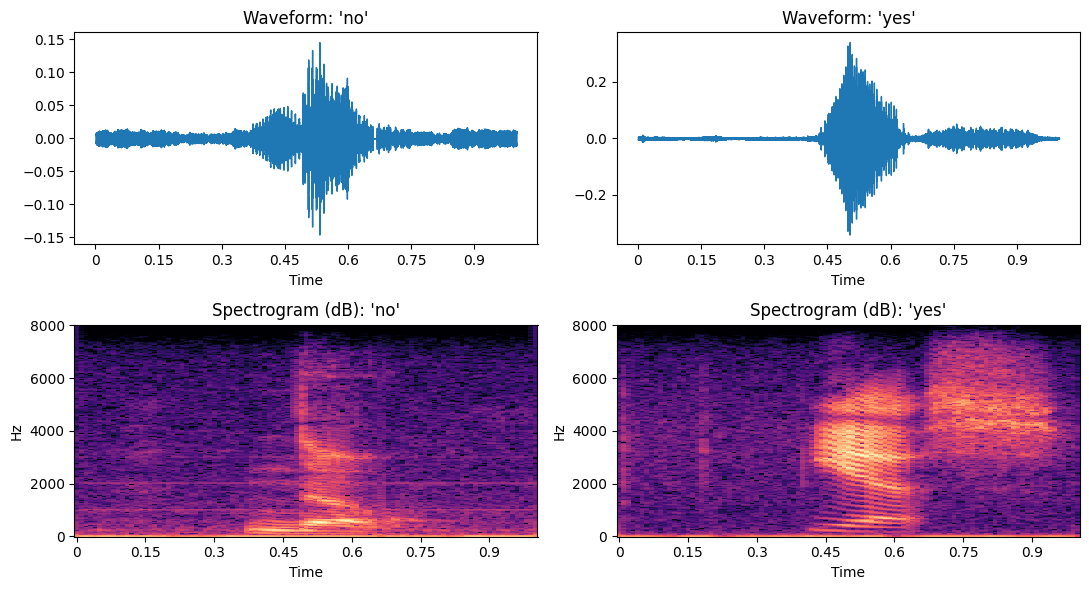

Sample rate used: 16000 Hz | clip length: 16000 samples


In [5]:
def load_fixed(path):
    y, sr = sf.read(path, dtype="float32", always_2d=False)
    if y.ndim > 1: y = y.mean(1)
    if sr != SR: y = librosa.resample(y, orig_sr=sr, target_sr=SR)
    return librosa.util.fix_length(y, size=N)

fig, ax = plt.subplots(2, 2, figsize=(11, 6))
for j, c in enumerate(CLASSES):
    y = load_fixed(df[df.label == c].path.iloc[0])
    librosa.display.waveshow(y, sr=SR, ax=ax[0, j]); ax[0, j].set_title(f"Waveform: '{c}'")
    S = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=512, hop_length=160)), ref=np.max)
    librosa.display.specshow(S, sr=SR, hop_length=160, x_axis="time", y_axis="hz", ax=ax[1, j])
    ax[1, j].set_title(f"Spectrogram (dB): '{c}'")
plt.tight_layout(); plt.savefig(OUT / "signal_spectrogram.png", dpi=150); plt.show()
print("Sample rate used:", SR, "Hz | clip length:", N, "samples")

## 4. Feature extraction
128-D vector per clip: mean/std of 20 MFCCs, Δ and ΔΔ (120 dims) + mean/std of ZCR, spectral centroid, spectral roll-off and RMS (8 dims). Clips are peak-normalised and padded/truncated to 1 s.

In [6]:
def extract(path):
    y = load_fixed(path)
    y = y / (np.max(np.abs(y)) + 1e-8)
    m = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=20, n_fft=512, hop_length=160)
    d1, d2 = librosa.feature.delta(m), librosa.feature.delta(m, order=2)
    st = lambda a: np.concatenate([a.mean(1), a.std(1)])
    sc = lambda a: np.array([a.mean(), a.std()])
    zcr  = librosa.feature.zero_crossing_rate(y, frame_length=512, hop_length=160)
    cent = librosa.feature.spectral_centroid(y=y, sr=SR, n_fft=512, hop_length=160)
    roll = librosa.feature.spectral_rolloff(y=y, sr=SR, n_fft=512, hop_length=160)
    rms  = librosa.feature.rms(y=y, frame_length=512, hop_length=160)
    return np.concatenate([st(m), st(d1), st(d2), sc(zcr), sc(cent), sc(roll), sc(rms)]).astype(np.float32)

CACHE = OUT / "features.npz"
if CACHE.exists():
    X = np.load(CACHE)["X"]
    assert len(X) == len(df), "Stale cache: delete outputs/features.npz"
else:
    t0 = time.time()
    X = np.stack(Parallel(n_jobs=-1, verbose=5)(delayed(extract)(p) for p in df.path))
    np.savez_compressed(CACHE, X=X)
    print(f"Extraction time: {time.time() - t0:.1f}s")

y = df.y.values
tr, va, te = [np.where(df.split.values == s)[0] for s in ("train", "val", "test")]
Xtr, ytr, Xva, yva, Xte, yte = X[tr], y[tr], X[va], y[va], X[te], y[te]
print("Feature matrix:", X.shape, "| NaNs:", int(np.isnan(X).sum()))

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:   11.7s
[Parallel(n_jobs=-1)]: Done 532 tasks      | elapsed:   15.5s
[Parallel(n_jobs=-1)]: Done 1972 tasks      | elapsed:   26.8s
[Parallel(n_jobs=-1)]: Done 3988 tasks      | elapsed:   42.4s
[Parallel(n_jobs=-1)]: Done 6580 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 7985 out of 7985 | elapsed:  1.2min finished


Extraction time: 73.0s
Feature matrix: (7985, 128) | NaNs: 0


## 5. Models and hyperparameter tuning
Each grid is searched by fitting on **train** and scoring macro-F1 on **validation**. The test set is not touched here.

In [7]:
spaces = {
    "SVM (RBF)": (lambda **p: make_pipeline(StandardScaler(),
                    SVC(kernel="rbf", class_weight="balanced", random_state=SEED, **p)),
                  {"C": [1, 10, 100], "gamma": ["scale", 1e-2, 1e-3]}),
    "Neural Network (MLP)": (lambda **p: make_pipeline(StandardScaler(),
                    MLPClassifier(early_stopping=True, max_iter=500, random_state=SEED, **p)),
                  {"hidden_layer_sizes": [(128,), (128, 64)], "alpha": [1e-4, 1e-2]}),
    "Random Forest": (lambda **p: RandomForestClassifier(n_estimators=300, class_weight="balanced",
                    n_jobs=-1, random_state=SEED, **p),
                  {"max_depth": [None, 20]}),
    "k-NN": (lambda **p: make_pipeline(StandardScaler(), KNeighborsClassifier(**p)),
             {"n_neighbors": [3, 5, 11, 21], "weights": ["uniform", "distance"]}),
    "Logistic Regression": (lambda **p: make_pipeline(StandardScaler(),
                    LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED, **p)),
                  {"C": [0.1, 1, 10]}),
}

def scores(m, X_):
    if hasattr(m, "predict_proba"): return m.predict_proba(X_)[:, 1]
    return m.decision_function(X_)

fitted, best_params, val_f1, fit_time = {}, {}, {}, {}
for name, (factory, grid) in spaces.items():
    best = (-1, None, None, None)
    for p in ParameterGrid(grid):
        t0 = time.time()
        m = factory(**p).fit(Xtr, ytr)
        f = f1_score(yva, m.predict(Xva), average="macro")
        if f > best[0]: best = (f, p, m, time.time() - t0)
    val_f1[name], best_params[name], fitted[name], fit_time[name] = best
    print(f"{name:22s} val macro-F1 = {best[0]:.4f}  best = {best[1]}")

SVM (RBF)              val macro-F1 = 0.9726  best = {'C': 100, 'gamma': 0.001}
Neural Network (MLP)   val macro-F1 = 0.9664  best = {'alpha': 0.01, 'hidden_layer_sizes': (128,)}
Random Forest          val macro-F1 = 0.9240  best = {'max_depth': None}
k-NN                   val macro-F1 = 0.9276  best = {'n_neighbors': 21, 'weights': 'uniform'}
Logistic Regression    val macro-F1 = 0.9564  best = {'C': 0.1}


## 6. Test-set evaluation (single pass)

In [8]:
def boot_ci(y_true, y_pred, B=2000):
    rng = np.random.default_rng(SEED); n = len(y_true)
    accs = [accuracy_score(y_true[i], y_pred[i]) for i in (rng.integers(0, n, n) for _ in range(B))]
    return np.percentile(accs, [2.5, 97.5])

rows, preds = [], {}
for name, m in fitted.items():
    p = m.predict(Xte); preds[name] = p
    lo, hi = boot_ci(yte, p)
    rows.append({"Model": name,
                 "Val F1": val_f1[name],
                 "Test Acc": accuracy_score(yte, p),
                 "95% CI": f"[{lo:.4f}, {hi:.4f}]",
                 "Precision": precision_score(yte, p, average="macro"),
                 "Recall": recall_score(yte, p, average="macro"),
                 "Macro-F1": f1_score(yte, p, average="macro"),
                 "ROC-AUC": roc_auc_score(yte, scores(m, Xte)),
                 "Train time (s)": fit_time[name]})
res = pd.DataFrame(rows).set_index("Model")
res.round(4).to_csv(OUT / "results_test.csv")
print(res.round(4).to_string())

for name in fitted:
    print(f"\n=== {name} ===")
    print(classification_report(yte, preds[name], target_names=CLASSES, digits=4))

                      Val F1  Test Acc            95% CI  Precision  Recall  Macro-F1  ROC-AUC  Train time (s)
Model                                                                                                         
SVM (RBF)             0.9726    0.9733  [0.9612, 0.9842]     0.9733  0.9734    0.9733   0.9964          0.9617
Neural Network (MLP)  0.9664    0.9818  [0.9721, 0.9903]     0.9818  0.9818    0.9818   0.9969          1.5403
Random Forest         0.9240    0.9211  [0.9017, 0.9393]     0.9212  0.9213    0.9211   0.9862         25.6840
k-NN                  0.9276    0.9417  [0.9260, 0.9575]     0.9420  0.9420    0.9417   0.9872          0.1610
Logistic Regression   0.9564    0.9769  [0.9660, 0.9867]     0.9769  0.9770    0.9769   0.9961          0.6929

=== SVM (RBF) ===
              precision    recall  f1-score   support

          no     0.9682    0.9778    0.9730       405
         yes     0.9783    0.9690    0.9736       419

    accuracy                         0.9

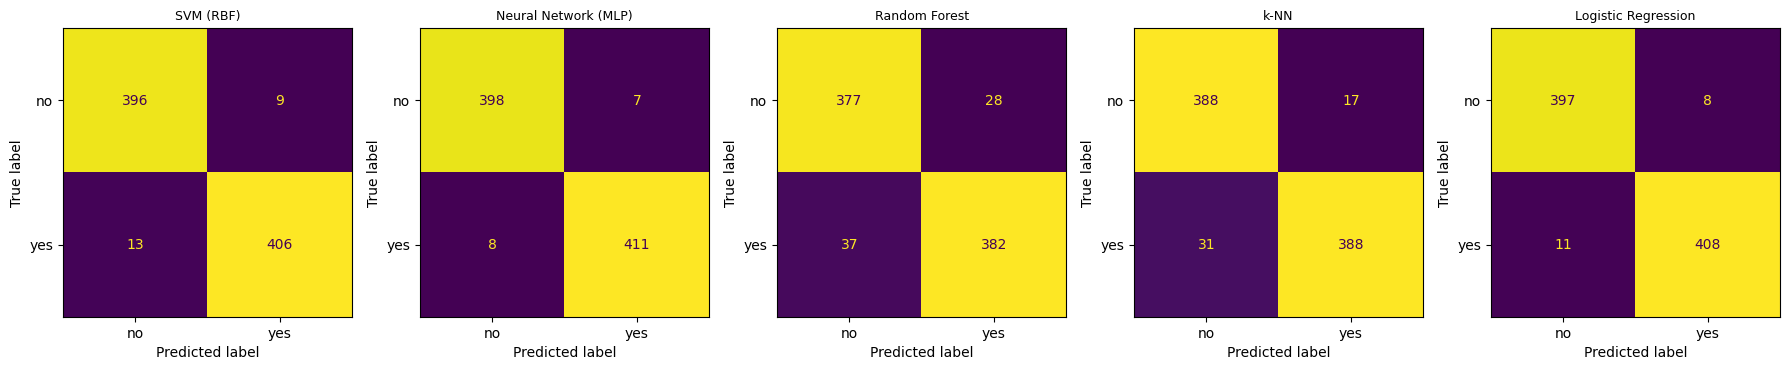

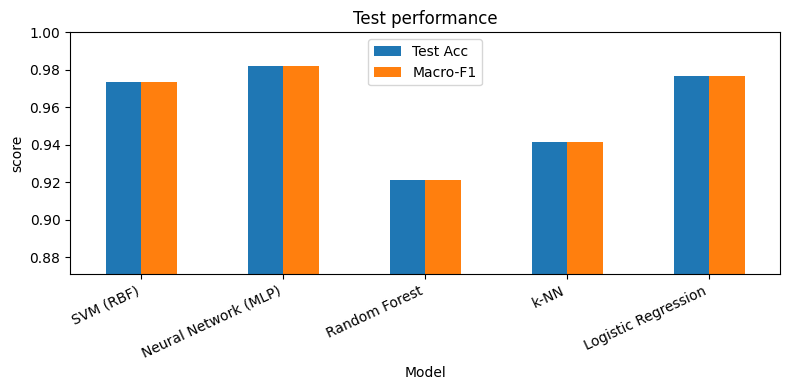

In [9]:
fig, ax = plt.subplots(1, len(fitted), figsize=(3.6 * len(fitted), 3.6))
for a, (name, p) in zip(np.atleast_1d(ax), preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(yte, p), display_labels=CLASSES).plot(ax=a, colorbar=False)
    a.set_title(name, fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "confusion_matrices.png", dpi=150); plt.show()

res[["Test Acc", "Macro-F1"]].plot.bar(figsize=(8, 4), ylim=(max(0, res["Test Acc"].min() - 0.05), 1.0))
plt.title("Test performance"); plt.ylabel("score"); plt.xticks(rotation=25, ha="right"); plt.tight_layout()
plt.savefig(OUT / "model_comparison.png", dpi=150); plt.show()

## 7. Cross-validation (stability of the comparison)
5-fold **GroupKFold** (grouped by speaker) on train+val using each model's tuned hyperparameters.

In [10]:
tv = np.concatenate([tr, va]); Xtv, ytv, gtv = X[tv], y[tv], df.speaker.values[tv]
cv_rows = []
for name, (factory, _) in spaces.items():
    accs, f1s = [], []
    for a, b in GroupKFold(n_splits=5).split(Xtv, ytv, gtv):
        m = factory(**best_params[name]).fit(Xtv[a], ytv[a]); p = m.predict(Xtv[b])
        accs.append(accuracy_score(ytv[b], p)); f1s.append(f1_score(ytv[b], p, average="macro"))
    cv_rows.append({"Model": name, "CV Acc": f"{np.mean(accs):.4f} ± {np.std(accs):.4f}",
                    "CV Macro-F1": f"{np.mean(f1s):.4f} ± {np.std(f1s):.4f}"})
cv = pd.DataFrame(cv_rows).set_index("Model")
cv.to_csv(OUT / "results_cv.csv"); print(cv.to_string())

                               CV Acc      CV Macro-F1
Model                                                 
SVM (RBF)             0.9564 ± 0.0059  0.9564 ± 0.0059
Neural Network (MLP)  0.9517 ± 0.0079  0.9517 ± 0.0079
Random Forest         0.9243 ± 0.0072  0.9243 ± 0.0072
k-NN                  0.9208 ± 0.0074  0.9208 ± 0.0074
Logistic Regression   0.9507 ± 0.0066  0.9507 ± 0.0066


## 8. Error analysis (best model by validation macro-F1)

In [11]:
best_name = max(val_f1, key=val_f1.get)
wrong = np.where(preds[best_name] != yte)[0]
err = pd.DataFrame({"file": df.rel.values[te][wrong],
                    "true": [CLASSES[i] for i in yte[wrong]],
                    "pred": [CLASSES[i] for i in preds[best_name][wrong]]})
err.to_csv(OUT / "misclassified.csv", index=False)
print(f"Best model (selected on validation): {best_name} | test errors: {len(err)} / {len(yte)}")
print(err.head(15).to_string(index=False))

Best model (selected on validation): SVM (RBF) | test errors: 22 / 824
                     file true pred
 no/1093c8e7_nohash_0.wav   no  yes
 no/28497c5b_nohash_0.wav   no  yes
 no/28497c5b_nohash_1.wav   no  yes
 no/3df9a3d4_nohash_0.wav   no  yes
 no/5e3dde6b_nohash_3.wav   no  yes
 no/6f689791_nohash_0.wav   no  yes
 no/8a325749_nohash_0.wav   no  yes
 no/97f4c236_nohash_2.wav   no  yes
 no/c22d3f18_nohash_4.wav   no  yes
yes/18f8afd5_nohash_1.wav  yes   no
yes/1cb788bc_nohash_0.wav  yes   no
yes/27c30960_nohash_0.wav  yes   no
yes/475b61f1_nohash_0.wav  yes   no
yes/893705bb_nohash_4.wav  yes   no
yes/893705bb_nohash_7.wav  yes   no
